# 03 · Which k stations should Ulaanbaatar keep? (GA vs alternatives)

**Decision:** keep a subset S of the eligible stations. Dropped stations are estimated each day from the kept ones (ridge regression on log PM2.5).

**Fitness (lower is better):** `F(S) = mean wRMSE of dropped stations / σ + λ · MissRate`
- wRMSE: error in µg/m³, days above the threshold weigh 3×
- MissRate: share of exceedance days at dropped stations that the reduced network would predict as clean

**Protocol:** models fit on **train** (Oct–Dec 2025), subsets chosen on **validation** (Jan 2026).
The **test** months (Feb–Mar 2026) are scored once, in the last section, on 23 November.

Logic: `src/uaq/network.py`.

In [1]:
# Setup: works whether or not you ran `pip install -e .`
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().resolve().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from uaq.config import load_config, ROOT
cfg = load_config()
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 200)
%matplotlib inline
print("Project root:", ROOT)

Project root: /Users/user/Desktop/neural


In [2]:
from uaq import audit_network as an, network
r = an.prepare(cfg)
fit = cfg["network"]["fitness"]
val_problem = network.Problem(r["wide"], r["masks"]["train"], r["masks"]["val"], r["threshold"], **fit)
print(f"{val_problem.n} stations, threshold {r['threshold']} µg/m³, σ = {val_problem.sigma:.1f}")

13 stations, threshold 37.5 µg/m³, σ = 40.0


## 1 · What one fitness evaluation returns

In [3]:
example = network.spatial_spread(val_problem, 4, r["lat"], r["lon"])
print("Subset:", val_problem.names(example))
val_problem.details(example)

Subset: ['12303', '12603', '12605', '12901']


{'F': 0.994585950472862,
 'wrmse': 37.2526442214032,
 'miss_rate': 0.1276595744680851,
 'events': 188,
 'missed': 24,
 'false_alarms': 8}

## 2 · Every method at every k (validation month)
Random = median of 1,000 random subsets (the "no method" baseline); exhaustive = the true optimum; GA = best of 10 seeds.
This takes about 20 seconds.

In [4]:
k_values = range(cfg["network"]["k_min"], val_problem.n)
res = network.compare(val_problem, k_values, cfg, r["lat"], r["lon"])
table = res.pivot(index="k", columns="method", values="F")
table["random (median)"] = res[res.method.str.startswith("random")].set_index("k")["random_median_F"]
table = table.drop(columns="random (best of draws)")
table.round(3)

method,exhaustive (optimum),genetic algorithm,greedy forward,highest mean,spatial spread,random (median)
k,,,,,,
3,0.503,0.503,0.527,0.577,0.926,0.811
4,0.420,0.420,0.462,0.541,0.995,0.760
5,0.386,0.386,0.405,0.586,0.916,0.743
6,0.352,0.352,0.352,0.597,0.905,0.724
7,0.319,0.319,0.319,0.566,0.850,0.721
8,0.295,0.295,0.295,0.608,0.607,0.714
9,0.270,0.270,0.270,0.673,0.310,0.712
10,0.238,0.238,0.238,0.405,0.367,0.715
11,0.216,0.216,0.216,0.603,0.355,0.691


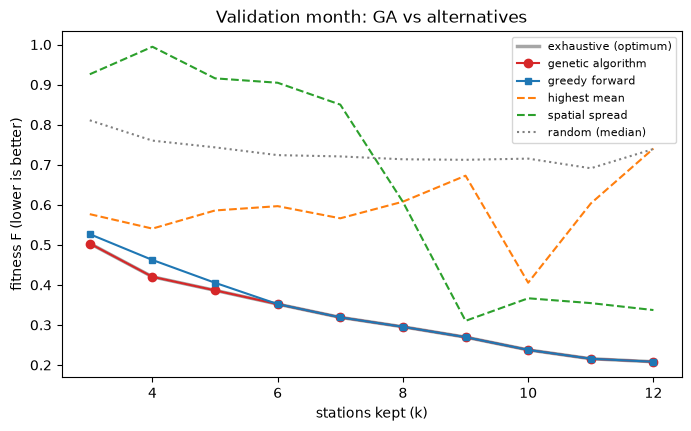

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5))
styles = {"exhaustive (optimum)": dict(color="k", lw=2.5, alpha=0.35), "genetic algorithm": dict(color="C3", marker="o"),
          "greedy forward": dict(color="C0", marker="s", ms=4), "highest mean": dict(color="C1", ls="--"),
          "spatial spread": dict(color="C2", ls="--"), "random (median)": dict(color="grey", ls=":")}
for m, st in styles.items():
    if m in table:
        ax.plot(table.index, table[m], label=m, **st)
ax.set_xlabel("stations kept (k)"); ax.set_ylabel("fitness F (lower is better)")
ax.set_title("Validation month: GA vs alternatives"); ax.legend(fontsize=8); plt.show()

## 3 · How close is each method to the optimum?

In [6]:
opt = table["exhaustive (optimum)"]
gap = ((table.drop(columns="exhaustive (optimum)").sub(opt, axis=0)).div(opt, axis=0) * 100).round(1)
gap.columns = [c + " gap %" for c in gap.columns]
gap

,genetic algorithm gap %,greedy forward gap %,highest mean gap %,spatial spread gap %,random (median) gap %
k,,,,,
3,0.0,4.6,14.6,84.0,61.1
4,0.0,10.0,28.6,136.7,80.9
5,0.0,4.9,51.6,137.0,92.4
6,0.0,0.0,69.5,157.0,105.7
7,0.0,0.0,77.6,166.6,126.0
8,0.0,0.0,105.8,105.6,141.6
9,0.0,0.0,149.6,15.1,164.3
10,0.0,0.0,70.6,54.2,200.9
11,0.0,0.0,179.8,64.4,220.6


In [7]:
ga = res[res.method == "genetic algorithm"].set_index("k")
ga[["F", "ga_seed_F_mean", "ga_seed_F_worst", "seconds"]].round(4)

,F,ga_seed_F_mean,ga_seed_F_worst,seconds
k,,,,
3,0.5033,0.5033,0.5033,0.11
4,0.4202,0.4202,0.4202,0.11
5,0.3863,0.3863,0.3863,0.11
6,0.3520,0.3520,0.3520,0.11
7,0.3189,0.3189,0.3189,0.11
8,0.2953,0.2953,0.2953,0.11
9,0.2695,0.2695,0.2695,0.12
10,0.2377,0.2377,0.2377,0.12
11,0.2156,0.2156,0.2156,0.12


## 4 · GA convergence (one k)

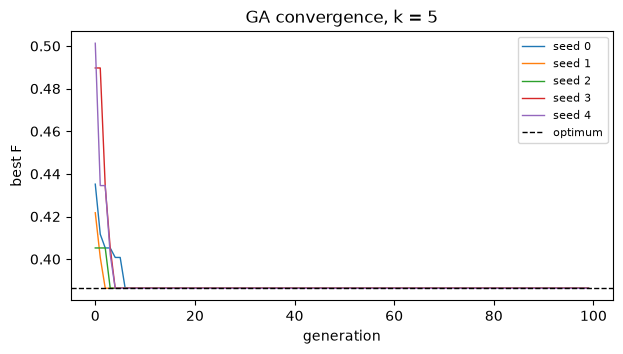

In [8]:
k = 5
fig, ax = plt.subplots(figsize=(7, 3.5))
for seed in cfg["network"]["ga"]["seeds"][:5]:
    _, _, hist = network.genetic_algorithm(val_problem, k, np.random.default_rng(seed),
                                           **{a: b for a, b in cfg["network"]["ga"].items() if a != "seeds"})
    ax.plot(hist, lw=1, label=f"seed {seed}")
ax.axhline(opt[k], color="k", ls="--", lw=1, label="optimum")
ax.set_xlabel("generation"); ax.set_ylabel("best F"); ax.set_title(f"GA convergence, k = {k}"); ax.legend(fontsize=8)
plt.show()

## 5 · Which stations does the GA keep?

In [9]:
names = r["stations"].set_index("station_code")["name_mn"]
chosen = ga["stations"].apply(lambda s: ", ".join(f"{c} {names[c]}" for c in s))
chosen.to_frame("GA subset")

,GA subset
k,
3,"12403 Баянхошуу-6, 12501 100 айл, 12901 Налайх"
4,"12301 Бөхийн өргөө, 12403 Баянхошуу-6, 12501 1..."
5,"12301 Бөхийн өргөө, 12403 Баянхошуу-6, 12501 1..."
6,"12403 Баянхошуу-6, 12501 100 айл, 12504 Дамбад..."
7,"12303 Ургах наран, 12403 Баянхошуу-6, 12501 10..."
8,"12303 Ургах наран, 12403 Баянхошуу-6, 12501 10..."
9,"12303 Ургах наран, 12403 Баянхошуу-6, 12501 10..."
10,"12301 Бөхийн өргөө, 12303 Ургах наран, 12403 Б..."
11,"12301 Бөхийн өргөө, 12303 Ургах наран, 12403 Б..."


## 6 · Sensitivity to λ (weight on missed exceedances)
Does the recommended subset change if missed high-pollution days matter more or less?

In [10]:
rows = []
for lam in (0.0, 0.5, 1.0):
    p = network.Problem(r["wide"], r["masks"]["train"], r["masks"]["val"], r["threshold"], **{**fit, "lambda_miss": lam})
    for k in (3, 5, 7):
        S = network.exhaustive(p, k)
        rows.append({"lambda": lam, "k": k, "stations": ", ".join(p.names(S)), **{a: round(b, 3) for a, b in p.details(S).items()}})
pd.DataFrame(rows)

,lambda,k,stations,F,wrmse,miss_rate,events,missed,false_alarms
0,0.0,3,"12403, 12501, 12901",0.453,18.143,0.100,180,18,31
1,0.0,5,"12301, 12403, 12501, 12504, 12901",0.330,13.189,0.114,132,15,19
2,0.0,7,"12303, 12403, 12501, 12504, 12602, 12801, 12901",0.284,11.351,0.071,85,6,15
3,0.5,3,"12403, 12501, 12901",0.503,18.143,0.100,180,18,31
4,0.5,5,"12301, 12403, 12501, 12504, 12901",0.386,13.189,0.114,132,15,19
5,0.5,7,"12303, 12403, 12501, 12504, 12602, 12801, 12901",0.319,11.351,0.071,85,6,15
6,1.0,3,"12403, 12501, 12801",0.549,19.295,0.067,179,12,27
7,1.0,5,"12303, 12403, 12501, 12602, 12901",0.431,14.951,0.057,140,8,25
8,1.0,7,"12303, 12403, 12501, 12504, 12602, 12801, 12901",0.354,11.351,0.071,85,6,15


## 7 · Save validation results

In [11]:
out = ROOT / "outputs" / "results"; out.mkdir(parents=True, exist_ok=True)
res.to_csv(out / "network_validation.csv", index=False)
print("Saved", out / "network_validation.csv")

Saved /Users/user/Desktop/neural/outputs/results/network_validation.csv


## 8 · FINAL TEST (run once, on 23 November)
Refit on train + validation, score the subsets each method chose on **validation** against the sealed Feb–Mar 2026 data.
Set `RUN_TEST = True` only once the forecasting model is also frozen. Do not change anything above after running this.

In [12]:
RUN_TEST = False

if RUN_TEST:
    m = r["masks"]
    test_problem = network.Problem(r["wide"], m["train"] | m["val"], m["test"], r["threshold"], **fit)
    idx = {c: i for i, c in enumerate(test_problem.stations)}
    rows = []
    for _, row in res.iterrows():
        S = tuple(idx[c] for c in row["stations"])
        rows.append({"k": row["k"], "method": row["method"], **test_problem.details(S)})
    test_res = pd.DataFrame(rows)
    test_res.to_csv(out / "network_test.csv", index=False)
    display(test_res.pivot(index="k", columns="method", values="F").round(3))
else:
    print("Test set still sealed.")

Test set still sealed.
